In [22]:
!pip install kagglehub

In [31]:
import kagglehub
path = kagglehub.dataset_download("yasserh/housing-prices-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'housing-prices-dataset' dataset.
Path to dataset files: /kaggle/input/housing-prices-dataset


In [32]:
import pandas as pd
import os

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All required libraries imported successfully!")

csv_path = os.path.join(path, "Housing.csv")

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")

All required libraries imported successfully!
Dataset loaded successfully!


In [33]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [34]:
print("Rows and Columns:", df.shape)

Rows and Columns: (545, 13)


In [35]:
print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

Number of rows and columns:
(545, 13)

Column names:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  pr

In [36]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [37]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate records:
0


In [38]:
X = df[['area']]

y = df['price']

print("Input Feature:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Feature:
   area
0  7420
1  8960
2  9960
3  7500
4  7420

Target Variable:
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


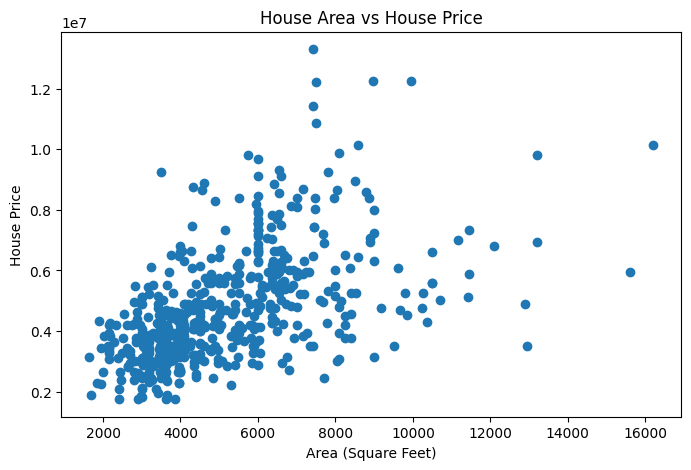

In [39]:
plt.figure(figsize=(8,5))

plt.scatter(df['area'], df['price'])

plt.title("House Area vs House Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("House Price")

plt.show()

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (436, 1)
Testing data: (109, 1)


In [41]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [42]:
print("Coefficient:", model.coef_[0])

print("Intercept:", model.intercept_)

Coefficient: 425.72984193878284
Intercept: 2512254.2639593435


In [ ]:
y_pred = model.predict(X_test)

print("Predicted Prices:")
print(y_pred[:10])

Predicted Prices:
[5024060.33139816 5279498.23656143 4232202.82539203 4640903.47365326
 4198144.43803692 5373158.80178796 6139472.51727777 4636646.17523387
 3891618.951841   3661724.83719406]


In [ ]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0       4060000     5.024060e+06
1       6650000     5.279498e+06
2       3710000     4.232203e+06
3       6440000     4.640903e+06
4       2800000     4.198144e+06
5       4900000     5.373159e+06
6       5250000     6.139473e+06
7       4543000     4.636646e+06
8       2450000     3.891619e+06
9       3353000     3.661725e+06


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2)

Mean Absolute Error: 1474748.1337969352
Mean Squared Error: 3675286604768.185
Root Mean Squared Error: 1917103.7021424233
R2 Score: 0.27287851871974644


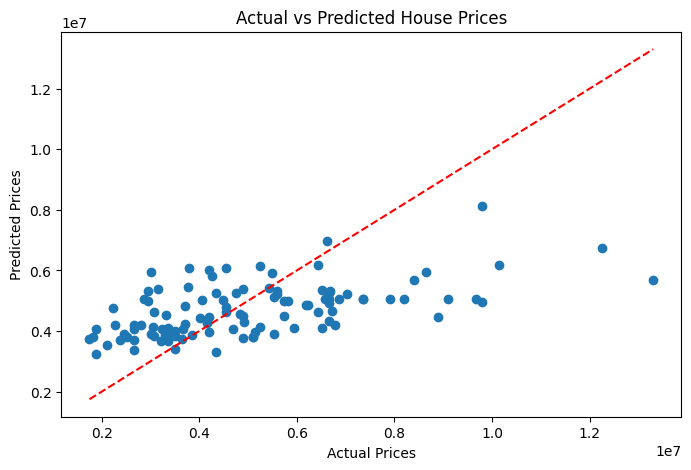

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title("Actual vs Predicted House Prices")

plt.xlabel("Actual Prices")

plt.ylabel("Predicted Prices")

plt.show()

In [ ]:
new_house = pd.DataFrame({
    'area': [5000]
})

predicted_price = model.predict(new_house)

print("Area of New House: 5000 Square Feet")

print("Predicted House Price:", predicted_price[0])

Area of New House: 5000 Square Feet
Predicted House Price: 4640903.473653258


In [ ]:
print("CONCLUSION")

print("House Price Prediction using Linear Regression completed.")

print("The model predicts house prices using house area.")

print("Model R2 Score:", r2)

print("Model evaluation completed successfully.")

CONCLUSION
House Price Prediction using Linear Regression completed.
The model predicts house prices using house area.
Model R2 Score: 0.27287851871974644
Model evaluation completed successfully.
